# Lab 03 - Deep Learning
## Lab/Tutorial in Canvas:
### 1. Read a Tutorial

Your First Deep Learning Project in Python with Keras Step-by-Step. (https://machinelearningmastery.com/tutorial-first-neural-network-python-keras/)

### 2. Learn by Example

This lab task uses the classic Auto MPG (For details: https://archive.ics.uci.edu/ml/datasets/auto+mpg). Dataset and builds a model to predict the fuel efficiency of late-1970s and early 1980s automobiles. The dataset provides the model with a description of many automobiles from that time period, and this description includes attributes: cylinders, displacement, horsepower, and weight. This example uses the `tf.keras` API, see this guide (https://www.tensorflow.org/guide/keras). for details.

You may use the notebook via google collab. (https://www.tensorflow.org/tutorials/keras/regression)

### 3. Solve on Your Own

Follow the above example and use the Medical Insurance Price Prediction (https://www.kaggle.com/datasets/harishkumardatalab/medical-insurance-price-prediction). dataset from Kaggle to predict medical insurance costs. You must include:

* Feature normalisation
* Linear regression with one feature
* Multiple linear regression
* Deep neural network (DNN) - single feature
* Deep neural network (DNN) - multiple features
* Performance comparison using metrics such as mean absolute error (MAE)
* Visualisation of predictions from the best-performing model

Please submit your completed code on Canvas > Assignments.

## Lab 3 Objective

The objective of this lab is to predict medical insurance charges
using patient-related features.

This is a regression problem because the target variable, `charges`,
is a continuous numerical value.

## Machine Learning Workflow

1. Understand the dataset
2. Clean the data
3. Explore the features and target
4. Encode categorical features
5. Prepare X and y
6. Split the data into training and testing sets
7. Normalise the features
8. Train Linear Regression models
9. Train DNN models
10. Compare model performance
11. Visualise predictions from the best model
12. Draw conclusions

# Part 1: Import Libraries and Load Dataset

## 1.1 Import Libraries

Before working with the dataset, we import the Python libraries needed for
data manipulation and visualisation.

- `pandas` → work with tabular data
- `numpy` → numerical operations
- `matplotlib.pyplot` → create visualisations

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1.2 Load the Dataset

The dataset contains information about people and their medical insurance
charges.

Our goal is to use the available features to predict `charges`.

We load the CSV file into a pandas DataFrame called `df`.
From that, we can see that the dataset contains information such as:

- `age`
- `sex`
- `bmi`
- `children`
- `smoker`
- `region`
- `charges`

The column `charges` is the value we eventually want our ML models to predict.

In [ ]:
try:
    from google.colab import drive  # only exists inside Colab
    drive.mount('/content/drive')
    # Adjust the path if your file is in a different Drive folder.
    file_path = '/content/drive/MyDrive/COS30082/Lab03/Medical_insurance.csv'
except ImportError:
    # Not in Colab -> CSV should be in the same folder as this notebook.
    file_path = 'Medical_insurance.csv'

df = pd.read_csv(file_path)

df.head() # displays the first five rows of the dataset

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# Part 2: Understand the Dataset

## 2.1 Dataset structure

Before cleaning or training a model, we need to understand what is inside
the dataset.
The info tells us:
- how many rows and columns exist
- the column names
- how many non-null values each column contains
- the data type of each column

In [ ]:
df.info() # Explains: number of rows, columns, non-null counts, data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   object 
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   object 
 5   region    2772 non-null   object 
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 151.7+ KB


Look at the data types.

Which columns do you expect to be numerical?
Which columns do you expect to be categorical/text?
Will a machine learning model be able to directly use values such as
`male`, `female`, `yes`, and `no`?

From what we discovered, The dataset contains 7 columns.

Numerical columns include:

- `age`
- `bmi`
- `children`
- `charges`

Categorical columns include:

- `sex`
- `smoker`
- `region`

The categorical columns will need to be encoded into numerical values before
they can be used by our ML models.

## 2.2 Describe the Numerical Data

We will use `df.describe()` gives us statistical information about numerical columns in the medical insurance dataset.

When run, it shows:

- `count`
- `mean`
- `std`
- `min`
- `25%`
- `50%`
- `75%`
- `max`

This helps us understand the range and distribution of the numerical data.

In [ ]:
df.describe() # explain numerical vs categorical data

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


### What Did We Discover?

For example, `charges` has:

- minimum ≈ 1,121.87
- median ≈ 9,333.01
- maximum ≈ 63,770.43

The large difference between the minimum and maximum suggests that insurance
charges vary substantially between people.

### Think

If one person has a charge of about $1,000 and another has a charge of
about \$60,000, would you expect predicting insurance charges to be a
completely simple problem?




## 2.3 Missing values
### Finding

Machine learning models generally cannot directly work with missing values
in the same way as complete numerical data.

Therefore, we check whether any columns contain missing values before training.

Every column has `0` missing values.
Therefore, no missing-value treatment is required for this dataset.

However, we still need to check for another common data-quality problem:
duplicate rows.

In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


# Part 3: Data Cleaning

## 3.1 Check duplicate rows
Why are duplicates potentially problematic?

Duplicate rows mean that the same observation appears more than once.

If duplicates are accidentally included during training, some observations may
have more influence than they should.

Therefore, we check how many duplicate rows exist.

In [ ]:
print(df.duplicated())
print("duplicate rows:", df.duplicated().sum())

0       False
1       False
2       False
3       False
4       False
        ...  
2767     True
2768     True
2769     True
2770     True
2771     True
Length: 2772, dtype: bool
duplicate rows: 1435



The dataset contains **1,435 duplicate rows**.

This is a large number compared with the original dataset size, so we should
remove the duplicates before continuing.

## 3.2 Remove duplicates
Since duplicate rows were found, we need to remove them.

`reset_index(drop=True)` also resets the row index after the duplicated
observations have been removed.

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Dataset shape after removing duplicates: (1337, 7)
Duplicate rows remaining: 0


The dataset now contains 1,337 rows and 7 columns.
The duplicate count is now 0.

We can therefore continue exploring the cleaned dataset.

# Part 4: Explore the Data



## 4.1 Re-check the Numerical Data

After removing duplicates, we should look at the numerical statistics again.

This allows us to understand the cleaned dataset before preparing it for
machine learning.

In [ ]:
print(df.describe().round(2))

           age      bmi  children   charges
count  1337.00  1337.00   1337.00   1337.00
mean     39.22    30.66      1.10  13279.12
std      14.04     6.10      1.21  12110.36
min      18.00    15.96      0.00   1121.87
25%      27.00    26.29      0.00   4746.34
50%      39.00    30.40      1.00   9386.16
75%      51.00    34.70      2.00  16657.72
max      64.00    53.13      5.00  63770.43


## 4.2 Investigate the Distribution of Insurance Charges

We focus on `charges` because it is the target variable that our models
will eventually predict.

We examine its:

- mean
- median
- skewness

If the mean and median are very different, what might that tell us about
the distribution of insurance charges?

Does that suggest that most people have similar charges, or that some
people have much larger charges than others?

In [ ]:
print("Mean charges:",
      round(df["charges"].mean())
      )
print("Median charges:",
      round(df["charges"].median())
      )
print("Skew:",
      round(df["charges"].skew(), 2)
      )

Mean charges: 13279
Median charges: 9386
Skew: 1.52


### Results

The mean and median are different, indicating that the distribution of
insurance charges is not perfectly symmetric.

The skewness value gives us another indication of the shape of this
distribution.

This is useful because we now know that `charges` is not simply distributed
around one typical value.

## 4.3 Compare Smokers and Non-Smokers

### Question

Does smoking status appear to be related to medical insurance charges?

We can group the data by `smoker` and compare the `charges`.

In [ ]:
print(
    df.groupby("smoker")["charges"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(0)
)

        count     mean   median      min      max
smoker                                           
no       1063   8441.0   7346.0   1122.0  36911.0
yes       274  32050.0  34456.0  12829.0  63770.0


### What Did We Found?

The summary allows us to compare the distribution of insurance charges
between smokers and non-smokers.

If the average charge is substantially different between the two groups,
then `smoker` may be an important feature for predicting `charges`.

However, this is only an observation.

It does not prove that smoking is the only reason for the difference.
Other features may also contribute to the prediction.

## 4.4 Investigate Numerical Relationships

### Why?

Correlation can help us investigate whether numerical variables have a
linear relationship with `charges`.

We examine the numerical columns and their correlation with the target.

Which feature do you expect to have a stronger relationship with `charges`?

- age?
- bmi?
- children?

Why?

In [ ]:
print(
    df.corr(numeric_only=True)["charges"]
    .sort_values()
    .round(3)
)

children    0.067
bmi         0.198
age         0.298
charges     1.000
Name: charges, dtype: float64


The correlation values give us an initial indication of how strongly each
numerical feature is linearly associated with insurance charges.

However, correlation does not capture every possible relationship.

This is one reason why we will later compare different ML models.

# Part 5: Visualise the Dataset


## 5.1 Distribution of Insurance Charges

### Why?

Before building a prediction model, it is useful to understand how the target
variable `charges` is distributed.

A histogram shows how frequently different ranges of charges occur.

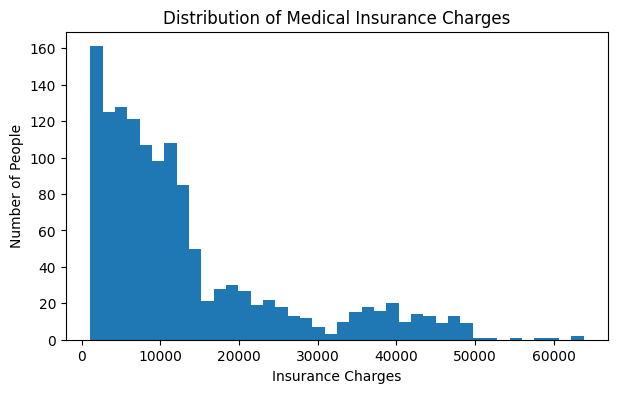

In [ ]:
plt.figure(figsize=(7, 4))

plt.hist(df["charges"], bins=40)

plt.xlabel("Insurance Charges")
plt.ylabel("Number of People")
plt.title("Distribution of Medical Insurance Charges")

plt.show()

### How to Read This Graph (When it runs)

- **x-axis** → insurance charge amount
- **y-axis** → number of people
- each bar → number of observations within a range of charges

The shape of the histogram helps us understand whether charges are
concentrated around a particular range or spread across a wide range.

## 5.2 Age vs Insurance Charges

### Why?

We now investigate whether age appears to be related to insurance charges.

A scatter plot represents each person as one point.

- x-axis → age
- y-axis → insurance charges
- each dot → one person

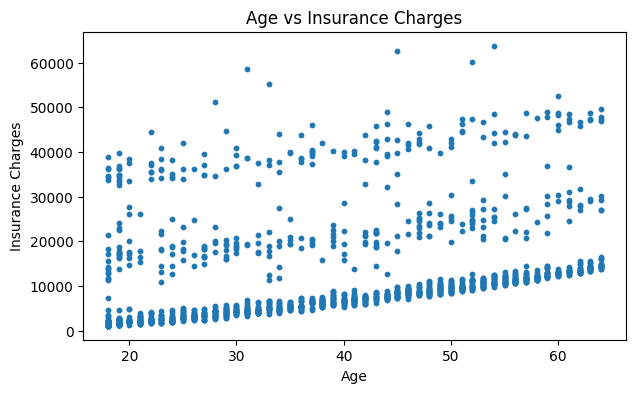

In [ ]:
plt.figure(figsize=(7, 4))

plt.scatter(df["age"], df["charges"], s=10)

plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.title("Age vs Insurance Charges")

plt.show()

Each dot represents one observation.

If the dots generally move upward as age increases, that suggests a positive
relationship between age and charges.

However, if the dots are widely scattered, age alone may not be enough to
accurately predict the insurance charge.

This is an important clue for our later comparison between:

- Linear Regression using one feature
- Linear Regression using multiple features
- DNN using one feature
- DNN using multiple features

## 5.3 BMI vs Insurance Charges

We can perform the same investigation for BMI.

This helps us determine whether BMI appears to contain useful information
for predicting insurance charges.

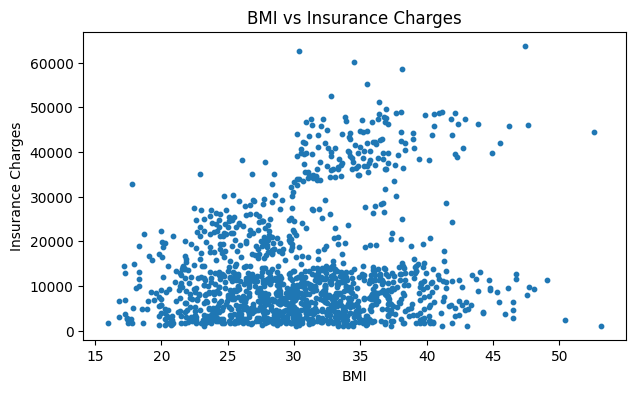

In [ ]:
plt.figure(figsize=(7, 4))

plt.scatter(df["bmi"], df["charges"], s=10)

plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.title("BMI vs Insurance Charges")

plt.show()

The scatter plot allows us to visually investigate the relationship between
BMI and insurance charges.

The points do not necessarily form a perfectly straight line.

This is useful to remember because later we will compare a simple linear
model with a deeper neural network.

# Part 6: Encode Categorical Features

## 6.1 Why Do We Need Encoding?

Our dataset contains categorical features such as:

- `sex`
- `smoker`
- `region`

These columns contain text values, but machine learning models require
numerical input.

Therefore, we need to convert the categorical values into numerical
representations before training our models.

For this project, we use **one-hot encoding** `pd.get_dummies()`.

One-hot encoding creates a separate binary column for each category.

For example:

- `smoker_yes = 1` means the person is a smoker.
- `smoker_yes = 0` means the person is not a smoker.

In [ ]:
df = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


## 6.2 Check the Encoded Features

After encoding, the original categorical columns have been replaced by
numerical dummy variables.

`drop_first=True` removes one category from each categorical feature to
avoid keeping redundant information.

The resulting columns should include:

- `sex_male`
- `smoker_yes`
- `region_northwest`
- `region_southeast`
- `region_southwest`

The remaining numerical features are:

- `age`
- `bmi`
- `children`
- `charges`

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1337 non-null   int64  
 1   bmi               1337 non-null   float64
 2   children          1337 non-null   int64  
 3   charges           1337 non-null   float64
 4   sex_male          1337 non-null   int64  
 5   smoker_yes        1337 non-null   int64  
 6   region_northwest  1337 non-null   int64  
 7   region_southeast  1337 non-null   int64  
 8   region_southwest  1337 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 94.1 KB


In [ ]:
df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


# Part 7: Prepare Features and Target



## 7.1 Separate Features (`X`) and Target (`y`)

Our goal is to predict medical insurance `charges`.

Therefore, we need to separate the dataset into two parts:

- **`X`** contains the input features used by the machine learning model.
- **`y`** contains the target value that the model is trying to predict.

The `charges` column must not be included in `X`, because it is the value
we are trying to predict.

If `charges` is the value we want the model to predict, what would happen
if we also gave `charges` to the model as one of its input features?

Would the model really be learning to predict the answer?

In [ ]:
X = df.drop("charges", axis=1)
y = df["charges"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1337, 8)
y shape: (1337,)


`X` contains the information available before predicting the insurance
charge, while `y` contains the actual insurance charge.

Including `charges` inside `X` would cause **target leakage** because the
model would receive the answer as an input.

We therefore keep the target separate from the input features.

## 7.2 Check the Features

Before training a model, we should verify that `X` contains only the
features we intend to use.

In [ ]:
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


In [ ]:
y.head()

,charges
0,16884.92400
1,1725.55230
2,4449.46200
3,21984.47061
4,3866.85520


In [ ]:
# Then we check the column names:
print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']

Target:
charges


### Key idea

Think of it like this:

`X` → information given to the model:
age + BMI + children + sex + smoker + region

`y` → answer the model must learn to predict:
insurance charges

## 7.3 Think About the Input and Target

Before continuing, check that you can identify the role of each variable.

- `X` → information given to the model
- `y` → value the model must predict

### Question

If `charges` were included in `X`, what problem would this create?

# Part 8: Train/Test Split



## 8.1 Why Do We Split the Data?

A machine learning model should not be evaluated only on the data it was
trained on.

We divide the dataset into two parts:

- **Training data**: used by the model to learn the relationship between
  the features and the target.
- **Testing data**: kept separate from training and used later to evaluate
  how well the model performs on unseen data.

This helps us determine whether the model can generalise to new observations.

### Before we run:

Suppose we use every row to train the model and then test the model on
those exact same rows.

Would a high performance score necessarily mean that the model can predict
charges for a new person?

Why might testing on unseen data give us a more useful evaluation?

## 8.2 Split the Dataset

We use `train_test_split()` from scikit-learn to randomly divide `X` and
`y` into training and testing sets.

We use 80% of the data for training and 20% for testing.

`random_state=42` makes the split reproducible, so we obtain the same
training and testing groups each time we run the notebook.

In [ ]:
# First, we import the function
from sklearn.model_selection import train_test_split

In [ ]:
# Then split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## 8.3 Check the Split

We now check the shape of each dataset to confirm that the split was
performed correctly.

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1069, 8)
X_test: (268, 8)
y_train: (1069,)
y_test: (268,)


The training data contains approximately 80% of the observations, while
the testing data contains approximately 20%.

Both `X` and `y` are split using the same random division. This keeps each
set's features matched with its corresponding target values.

The test data is now kept aside and will be used later to evaluate our
models.

## 8.4 Why Use `random_state=42`?

`random_state` controls the random process used to divide the data.

Using a fixed value such as `42` means that the same rows are selected for
the training and testing sets whenever the code is run again.

The number `42` itself has no special machine learning meaning. It is simply
a chosen seed value.

Without a fixed `random_state`, the split can change between runs, which
can cause model results to change slightly.

# Part 9: Feature Normalisation


## 9.1 Why Do We Need Normalisation?

Our features have very different numerical ranges.

For example:

- `age` ranges from about 18 to 64.
- `bmi` ranges from about 16 to 53.
- `children` ranges from 0 to 5.
- `smoker_yes` is only 0 or 1.

Feature normalisation transforms the input features to a more consistent
scale.

Normalisation is particularly useful for neural networks because it can
help the optimisation process train more effectively.

For this lab, we prepare the normalised features before training the
multi-feature models so that the Linear Regression and DNN experiments
can use the same prepared input representation.

Before we run:

Imagine two features:

- Feature A ranges from 0 to 1.
- Feature B ranges from 0 to 50,000.

If both are used by the same model, do you think their raw numerical scales
could affect the learning process?

What might happen if we put them onto a similar scale first?

## 9.2 Create the Normalisation Scaler

We use `MinMaxScaler` from scikit-learn to transform the features.

Min-max normalisation scales each feature to a range between 0 and 1.

The important point is that the scaler must be **fitted using the training
data only**.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

## 9.3 Fit the Scaler Using Training Data

We first learn the minimum and maximum values from `X_train`.

We then use those values to transform both `X_train` and `X_test`.

We do not fit the scaler using `X_test`, because the test data is supposed
to represent unseen data.

Using information from the test set during preprocessing would introduce
data leakage.

In [ ]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

`fit_transform()` does two things:

1. Learns the scaling parameters from the training data.
2. Applies the scaling.

`transform()` only applies the scaling parameters that were already learned
from the training data.

Therefore, the test set does not influence how the scaler is fitted.

## 9.4 Check the Normalised Data

We can inspect the first few rows of the scaled training data to confirm
that the transformation has been applied.

In [ ]:
print(X_train_scaled[:5])

[[0.10869565 0.23002421 0.         1.         0.         0.
  0.         0.        ]
 [0.06521739 0.26324993 0.4        1.         0.         0.
  0.         0.        ]
 [0.73913043 0.58017218 0.4        0.         0.         1.
  0.         0.        ]
 [0.97826087 0.68630616 0.         1.         0.         0.
  1.         0.        ]
 [0.63043478 0.28625235 0.4        0.         0.         0.
  0.         0.        ]]


In [ ]:
# And then we will check the range
print("Minimum:", X_train_scaled.min())
print("Maximum:", X_train_scaled.max())

Minimum: 0.0
Maximum: 1.0


From the output, The feature values have been transformed to a common scale.

The scaler was fitted only on the training data, which prevents information
from the test set from influencing the preprocessing step.

We now have:

- `X_train_scaled` → normalised training features
- `X_test_scaled` → normalised testing features
- `y_train` → training target
- `y_test` → testing target

These scaled features can now be used when training models that benefit
from normalised input.

# Part 10: Linear Regression

## 10.1 Linear Regression with One Feature

Linear Regression is a supervised learning algorithm used to predict a
continuous numerical target.

For our first experiment, we use only one feature: `age`.

The purpose of starting with one feature is to make the relationship between
the input and the predicted insurance charges easy to understand and
visualise.

The model learns a straight-line relationship between `age` and `charges`.

In [ ]:
from sklearn.linear_model import LinearRegression

X_one = df[["age"]]
y_one = df["charges"]

X_one_train, X_one_test, y_one_train, y_one_test = train_test_split(
    X_one,
    y_one,
    test_size=0.2,
    random_state=42
)

### Why `df[["age"]]` instead of `df["age"]`?

`df["age"]` produces a one-dimensional Series.

`df[["age"]]` produces a two-dimensional DataFrame containing one feature,
which is the format expected by most scikit-learn machine learning models
for `X`.

### Note

For this first Linear Regression experiment, we use the original `age`
values because Linear Regression does not require feature normalisation for
this task.

The DNN experiments will use normalised features because neural networks are
more sensitive to differences in feature scale during training.

## 10.2 Train the Model

In [ ]:
lr_one = LinearRegression()

lr_one.fit(X_one_train, y_one_train)

LinearRegression()

The Linear Regression model has learned a relationship between `age` and
the insurance charges in the training data.

The model has learned two important parameters:

- **coefficient**: determines the slope of the regression line
- **intercept**: determines where the line crosses the y-axis

In [ ]:
print("Coefficient:", lr_one.coef_[0])
print("Intercept:", lr_one.intercept_)

Coefficient: 242.25815190122503
Intercept: 3534.0917330710636


## 10.3 Make Predictions

The model has now been trained.

We use the test data, which the model did not see during training, to
generate predictions.

The model has learned a coefficient and an intercept that define the
regression line.

The coefficient represents how the predicted `charges` change when `age`
increases by one unit, according to this simple model.

Because we are using only `age`, the model cannot directly account for
other factors such as BMI, smoking status, or number of children.

In [ ]:
y_one_pred = lr_one.predict(X_one_test)

print(y_one_pred[:10])

[15404.74117623 10559.57813821 15889.25748003 11044.09444201
 11044.09444201 15404.74117623  9106.0292268   8863.7710749
 13951.19226482 15404.74117623]


In [ ]:
comparison_one = pd.DataFrame({
    "Actual": y_one_test.values,
    "Predicted": y_one_pred
})

comparison_one.head(10)

,Actual,Predicted
0,8688.85885,15404.741176
1,5708.86700,10559.578138
2,11436.73815,15889.257480
3,38746.35510,11044.094442
4,4463.20510,11044.094442
5,9304.70190,15404.741176
6,38511.62830,9106.029227
7,2150.46900,8863.771075
8,7345.72660,13951.192265
9,10264.44210,15404.741176


## 10.4 Evaluate Using Mean Absolute Error (MAE)

We use Mean Absolute Error (MAE) to measure how close the predictions are
to the actual insurance charges.

MAE calculates the average absolute difference between the predicted and
actual values.

A lower MAE means the model's predictions are closer to the actual values.

In [ ]:
from sklearn.metrics import mean_absolute_error

mae_lr_one = mean_absolute_error(
    y_one_test,
    y_one_pred
)

print("Linear Regression - One Feature MAE:", round(mae_lr_one, 2))

Linear Regression - One Feature MAE: 9657.79


## 10.5 Visualise the One-Feature Model

Because this model uses only one feature, we can visualise the relationship
between `age` and `charges`.

- X-axis → age
- Y-axis → insurance charges
- Each point → one person in the test set
- Line → predictions made by the Linear Regression model

The line shows the simple linear relationship learned by the model.

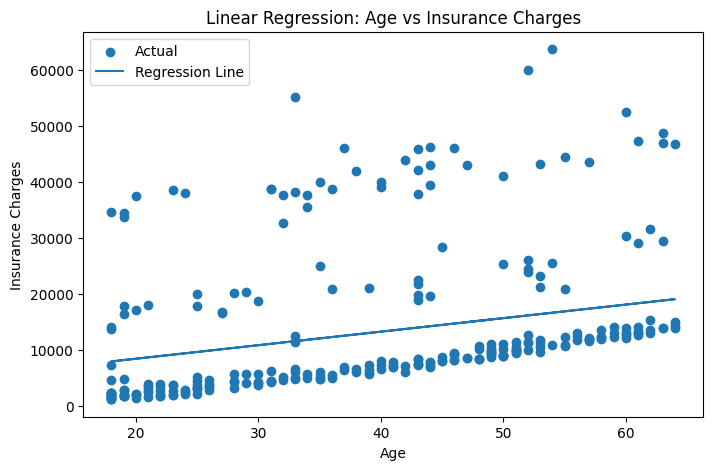

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_one_test["age"],
    y_one_test,
    label="Actual"
)

plt.plot(
    X_one_test["age"],
    y_one_pred,
    label="Regression Line"
)

plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.title("Linear Regression: Age vs Insurance Charges")
plt.legend()
plt.show()

Look at the scatter plot.

Do all observations follow the regression line closely?

If there is a large amount of variation around the line, can `age` alone
fully explain insurance charges?

What other features might provide useful information?

## 10.6 Multiple Linear Regression

The previous model used only `age`.

However, our dataset contains several other features that may provide
useful information for predicting insurance charges.

We therefore train a Multiple Linear Regression model using all eight
encoded features.

This allows us to investigate whether using more information improves
prediction performance.

In [ ]:
lr_multi = LinearRegression()

lr_multi.fit(
    X_train_scaled,
    y_train
)

LinearRegression()

## 10.7 Make Predictions and Evaluate

In [ ]:
y_multi_pred = lr_multi.predict(X_test_scaled)

mae_lr_multi = mean_absolute_error(
    y_test,
    y_multi_pred
)

print(
    "Linear Regression - Multiple Features MAE:",
    round(mae_lr_multi, 2)
)

Linear Regression - Multiple Features MAE: 4177.05


### What Did We Discover?
We now have two Linear Regression models:

1. **One feature**: uses only `age`
2. **Multiple features**: uses all available input features

Their MAE values allow us to determine whether adding more features
improved the model's predictions.

We will keep these MAE values and compare them with the DNN models later.

# Part 11: Deep Neural Network (DNN)

## 11.1 DNN with a Single Feature

A Deep Neural Network (DNN) contains layers of artificial neurons that
learn relationships between input features and a target.

We first build a DNN using only `age`, just as we did with Linear
Regression.

This gives us a fair comparison between the two model types when they
receive the same single feature.

In [ ]:
X_age = df[["age"]]
y_age = df["charges"]

X_age_train, X_age_test, y_age_train, y_age_test = train_test_split(
    X_age,
    y_age,
    test_size=0.2,
    random_state=42
)

age_scaler = MinMaxScaler()

X_age_train_scaled = age_scaler.fit_transform(X_age_train)
X_age_test_scaled = age_scaler.transform(X_age_test)

## 11.2 Build the DNN

In [ ]:
import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(42)
np.random.seed(42)

In [ ]:
dnn_one = keras.Sequential([
    keras.layers.Input(shape=(1,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1)
])

dnn_one.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

The network contains:

- an input layer receiving one feature (`age`)
- two hidden layers containing 16 neurons each
- an output layer containing one neuron for the predicted `charges`

The hidden layers use the ReLU activation function.

The final layer has one output because this is a regression problem: we need
one continuous predicted value.

### Understanding the DNN Architecture

The network uses:

- `Input(shape=(1,))` → receives one input feature, `age`
- `Dense(16, activation="relu")` → hidden layer with 16 neurons
- `Dense(16, activation="relu")` → another hidden layer
- `Dense(1)` → produces one continuous numerical prediction

The hidden layers use **ReLU** so that the network can learn non-linear
relationships.

The final layer has no activation function because this is a regression
problem and the output can take a wide range of continuous values.

The number of neurons and layers is a design choice for this experiment;
they can be changed and compared during model optimisation.

### Why Do We Use Adam, MSE and MAE?

The DNN is trained using:

- **Adam** as the optimiser, which updates the network weights during
  training.
- **MSE (Mean Squared Error)** as the training loss.
- **MAE (Mean Absolute Error)** as an evaluation metric.

We use MAE for the final model comparison because it is easy to interpret:
it represents the average absolute prediction error in the same units as
the insurance charges.

## 11.3 Train and Predict

In [ ]:
history_one = dnn_one.fit(
    X_age_train_scaled,
    y_age_train,
    epochs=100,
    validation_split=0.2,
    verbose=0
)

In [ ]:
y_dnn_one_pred = dnn_one.predict(
    X_age_test_scaled,
    verbose=0
).flatten()

## 11.4 Evaluate the DNN

In [ ]:
mae_dnn_one = mean_absolute_error(
    y_age_test,
    y_dnn_one_pred
)

print(
    "DNN - One Feature MAE:",
    round(mae_dnn_one, 2)
)

DNN - One Feature MAE: 8599.96


# Part 12: DNN with Multiple Features

## 12.1 Build the Multi-Feature DNN

We now train a DNN using all available features.

The network receives the eight normalised input features prepared earlier.

This allows the DNN to learn relationships involving multiple features
rather than relying only on `age`.

In [ ]:
dnn_multi = keras.Sequential([
    keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1)
])

dnn_multi.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

## 12.2 Train and Predict

In [ ]:
history_multi = dnn_multi.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    validation_split=0.2,
    verbose=0
)

In [ ]:
y_dnn_multi_pred = dnn_multi.predict(
    X_test_scaled,
    verbose=0
).flatten()

## 12.3 Evaluate the DNN

In [ ]:
mae_dnn_multi = mean_absolute_error(
    y_test,
    y_dnn_multi_pred
)

print(
    "DNN - Multiple Features MAE:",
    round(mae_dnn_multi, 2)
)

DNN - Multiple Features MAE: 6898.1


# Part 13: Model Performance Comparison

## 13.1 Compare MAE

We have trained four models using two different approaches and different
numbers of features.

We now compare their Mean Absolute Error (MAE).

Because all models are evaluated using test data, their MAE values provide
a common basis for comparison.

A lower MAE indicates smaller average prediction errors.

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression - One Feature",
        "Linear Regression - Multiple Features",
        "DNN - One Feature",
        "DNN - Multiple Features"
    ],
    "MAE": [
        mae_lr_one,
        mae_lr_multi,
        mae_dnn_one,
        mae_dnn_multi
    ]
})

results.sort_values("MAE").reset_index(drop=True)

,Model,MAE
0,Linear Regression - Multiple Features,4177.045561
1,DNN - Multiple Features,6898.100132
2,DNN - One Feature,8599.960979
3,Linear Regression - One Feature,9657.789350


### How to Interpret the Comparison

The MAE values should be compared using the same test dataset and the same
evaluation metric.

The model with the smallest MAE made the smallest average absolute
prediction error on the test data.

However, this does not mean that the model is universally the best model.
It is the best-performing model **for this experiment and this test set**.

## 13.2 Select the Best-Performing Model

The model with the lowest MAE is considered the best-performing model for
this experiment.

We identify it from the comparison table.

In [ ]:
best_model = results.loc[results["MAE"].idxmin()]

print("Best model:", best_model["Model"])
print("Best MAE:", round(best_model["MAE"], 2))

Best model: Linear Regression - Multiple Features
Best MAE: 4177.05


## 13.3 Visualise Predictions from the Best-Performing Model

The lab requires us to visualise the predictions made by the
best-performing model.

For regression, we can compare:

- actual insurance charges
- predicted insurance charges

If the predictions are accurate, the points should be close to the
diagonal line where:

    predicted charge = actual charge

In [ ]:
model_predictions = {
    "Linear Regression - One Feature": (
        y_one_test,
        y_one_pred
    ),
    "Linear Regression - Multiple Features": (
        y_test,
        y_multi_pred
    ),
    "DNN - One Feature": (
        y_age_test,
        y_dnn_one_pred
    ),
    "DNN - Multiple Features": (
        y_test,
        y_dnn_multi_pred
    )
}

best_name = best_model["Model"]

actual, predicted = model_predictions[best_name]

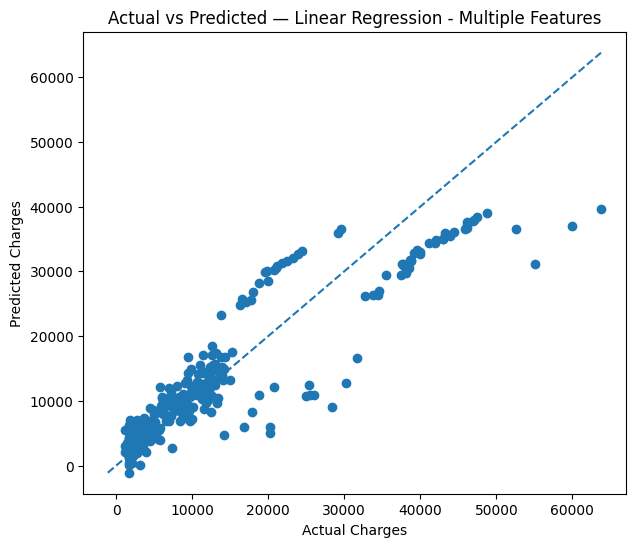

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(actual, predicted)

min_value = min(actual.min(), predicted.min())
max_value = max(actual.max(), predicted.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title(f"Actual vs Predicted — {best_name}")

plt.show()

### How to Read The Graph

Each point represents one test observation.

- X-axis → actual insurance charge
- Y-axis → predicted insurance charge
- Diagonal dashed line → perfect prediction

Points close to the diagonal indicate predictions close to the actual
charges.

Points further away from the diagonal represent larger prediction errors.

# Part 14: Conclusion

## 14.1 What We Did

In this project, we followed a complete machine learning workflow to predict
medical insurance charges.

We:

- prepared and cleaned the dataset
- explored and visualised the data
- encoded categorical features
- separated the features and target
- split the data into training and testing sets
- normalised the input features
- trained Linear Regression models
- trained DNN models
- compared four models using MAE
- identified the best-performing model
- visualised its predictions

## 14.2 Final Result

The model with the lowest MAE was the best-performing model in this
experiment.

The final prediction visualisation allows us to examine how closely its
predictions match the actual insurance charges.

The results demonstrate why model performance should be evaluated using
unseen test data rather than relying only on the training process.